> Check individual signals according to the community they belong.

In [1]:
import pathlib

import pandas as pd

import numpy as np
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve
from sklearn.covariance import EmpiricalCovariance

import jax
import jax.numpy as jnp
import jax.random as jr

from jaxtyping import Array, Float, Int

from torch.utils.data import DataLoader

import trapallada.util
import trapallada.results.analysis
import trapallada.model.training
import trapallada.model.nn

So that `import`ed Python modules are automatically reloaded when modified

In [2]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


So that *plotly*'s pictures are correctly rendered

In [3]:
import plotly.io as pio
pio.renderers.default = 'notebook'

# Parameters

Base directory

In [4]:
base_dir = trapallada.util.get_base_directory()
assert base_dir.exists()

Directory with all the files

In [5]:
# res_dir = base_dir / 'results' / 'multichannel' / 'rates_large_infs' / 'time_z_5'
# res_dir = base_dir / 'results' / 'beta' / 'rates_large_infs' / 'grid' / 'beta_0.01_dim_z_10'
res_dir = base_dir / 'results' / 'training_validation_split' / 'rates_large_infs' / 'grid' / 'beta_0.01_dim_z_10'
# res_dir = base_dir / 'results' / 'training_validation_split' / 'rates_large_infs' / 'grid' / 'beta_0.01_dim_z_5'
assert res_dir.exists()

*Sub*directory with the labels

In [6]:
# annotations_dir = res_dir / 'annotations'
annotations_dir = base_dir / 'annotations'
assert annotations_dir.exists()

The "selected by" file indicating the algorithm (VAE or AR) that selected every window.

In [7]:
selected_by_file = annotations_dir / 'signals_to_assess.parquet'
assert selected_by_file.exists()

The file with the annotations provided by Javi López Santiago.

In [8]:
annotations_file = annotations_dir / 'windows.xlsx'
assert annotations_file.exists()

Output file *merging* the above files

In [9]:
output_file = annotations_dir / 'annotated_windows.parquet'

*Windows* that were manually selected as representative of *signals* that were, in the beginning, marked as interesting.

In [10]:
reference_windows_file = annotations_dir / 'reference_windows.xlsx'

# Input data

The *selected by* `DataFrame` stating the algorithm (VAE or AR) that selected every window.

In [11]:
selected_by_df = pd.read_parquet(selected_by_file)
selected_by_df

,start,end,tar file,source,signal,Selected by
14796,2004-02-29 23:34:36.224518,2004-03-01 05:17:59.744518,0201360201.tar,P0201360201PNX000SRCTSR8002.FTZ,0201360201/P0201360201PNX000SRCTSR8002,VAE
25125,2015-05-25 05:07:30.919731,2015-05-25 10:50:54.439731,0770180201.tar,P0770180201PNX000SRCTSR8001.FTZ,0770180201/P0770180201PNX000SRCTSR8001,AR
15937,2011-01-03 19:00:05.711776,2011-01-04 00:43:29.231776,0652330101.tar,P0652330101PNX000SRCTSR8001.FTZ,0652330101/P0652330101PNX000SRCTSR8001,VAE
22425,2015-03-26 05:54:06.667239,2015-03-26 11:37:30.187239,0764800301.tar,P0764800301PNX000SRCTSR8005.FTZ,0764800301/P0764800301PNX000SRCTSR8005,NaN
29039,2015-06-27 04:31:17.762896,2015-06-27 10:14:41.282896,0761970101.tar,P0761970101PNX000SRCTSR8002.FTZ,0761970101/P0761970101PNX000SRCTSR8002,NaN
...,...,...,...,...,...,...
27106,2014-10-04 23:21:51.077119,2014-10-05 05:05:14.597119,0728990101.tar,P0728990101PNX000SRCTSR8001.FTZ,0728990101/P0728990101PNX000SRCTSR8001,AR
9253,2008-06-27 08:47:46.841629,2008-06-27 14:31:10.361629,0551750301.tar,P0551750301PNX000SRCTSR8001.FTZ,0551750301/P0551750301PNX000SRCTSR8001,AR
15049,2017-10-24 15:17:34.836966,2017-10-24 21:00:58.356966,0795730101.tar,P0795730101PNX000SRCTSR8001.FTZ,0795730101/P0795730101PNX000SRCTSR8001,VAE
5371,2013-09-27 21:06:30.736658,2013-09-28 02:49:54.256658,0724380101.tar,P0724380101PNX000SRCTSR8003.FTZ,0724380101/P0724380101PNX000SRCTSR8003,NaN


The `DataFrame` with the labels provided by the annotator. Its index (window *id*) must be the same as that of the above `DataFrame`. The label `Interesting` actually stands for something that has been identified, but it might just be `background` (i.e., noise).

In [12]:
# labels_df = pd.read_excel(labels_file)
labels_df = pd.read_excel(annotations_file)


# first column is just a "dummy" index (the number of the row)
labels_df = labels_df.drop(columns=labels_df.columns[0])

labels_df.index = selected_by_df.index
labels_df

,Label,Type,Subtype
14796,Interesting,doubleExponential,flare
25125,NaN,NaN,NaN
15937,Interesting,doubleExponential,flare
22425,Interesting,background,NaN
29039,NOT interesting,NaN,NaN
...,...,...,...
27106,NOT interesting,NaN,NaN
9253,NOT interesting,NaN,NaN
15049,Interesting,background,NaN
5371,NOT interesting,NaN,NaN


## Results

The `DataFrame`s with the labels and the `Selected by` column are merged together...

In [13]:
res_df = pd.concat((selected_by_df, labels_df), axis=1)
res_df

,start,end,tar file,source,signal,Selected by,Label,Type,Subtype
14796,2004-02-29 23:34:36.224518,2004-03-01 05:17:59.744518,0201360201.tar,P0201360201PNX000SRCTSR8002.FTZ,0201360201/P0201360201PNX000SRCTSR8002,VAE,Interesting,doubleExponential,flare
25125,2015-05-25 05:07:30.919731,2015-05-25 10:50:54.439731,0770180201.tar,P0770180201PNX000SRCTSR8001.FTZ,0770180201/P0770180201PNX000SRCTSR8001,AR,NaN,NaN,NaN
15937,2011-01-03 19:00:05.711776,2011-01-04 00:43:29.231776,0652330101.tar,P0652330101PNX000SRCTSR8001.FTZ,0652330101/P0652330101PNX000SRCTSR8001,VAE,Interesting,doubleExponential,flare
22425,2015-03-26 05:54:06.667239,2015-03-26 11:37:30.187239,0764800301.tar,P0764800301PNX000SRCTSR8005.FTZ,0764800301/P0764800301PNX000SRCTSR8005,NaN,Interesting,background,NaN
29039,2015-06-27 04:31:17.762896,2015-06-27 10:14:41.282896,0761970101.tar,P0761970101PNX000SRCTSR8002.FTZ,0761970101/P0761970101PNX000SRCTSR8002,NaN,NOT interesting,NaN,NaN
...,...,...,...,...,...,...,...,...,...
27106,2014-10-04 23:21:51.077119,2014-10-05 05:05:14.597119,0728990101.tar,P0728990101PNX000SRCTSR8001.FTZ,0728990101/P0728990101PNX000SRCTSR8001,AR,NOT interesting,NaN,NaN
9253,2008-06-27 08:47:46.841629,2008-06-27 14:31:10.361629,0551750301.tar,P0551750301PNX000SRCTSR8001.FTZ,0551750301/P0551750301PNX000SRCTSR8001,AR,NOT interesting,NaN,NaN
15049,2017-10-24 15:17:34.836966,2017-10-24 21:00:58.356966,0795730101.tar,P0795730101PNX000SRCTSR8001.FTZ,0795730101/P0795730101PNX000SRCTSR8001,VAE,Interesting,background,NaN
5371,2013-09-27 21:06:30.736658,2013-09-28 02:49:54.256658,0724380101.tar,P0724380101PNX000SRCTSR8003.FTZ,0724380101/P0724380101PNX000SRCTSR8003,NaN,NOT interesting,NaN,NaN


...and saved

In [14]:
res_df.to_parquet(output_file, index=True)

A new column which is `True` for every *event of interest*

In [15]:
res_df['Event'] = res_df.eval('Label == "Interesting" & Type != "background"')

How many windows of each label, including **unlabeled**

In [16]:
res_df['Label'].value_counts(dropna=False)

Label
Interesting        125
NOT interesting     69
NaN                  6
Name: count, dtype: int64

In [17]:
res_df['Event'].value_counts(dropna=False)

Event
False    115
True      85
Name: count, dtype: int64

Let us get rid of the undecided (`NaN`s)

In [18]:
res_df = res_df[~pd.isna(res_df['Label'])]
res_df.shape

(194, 10)

How many windows of each `Type`? Notice the `Type` of the `NOT interesting` is `NaN`

<Axes: xlabel='Type'>

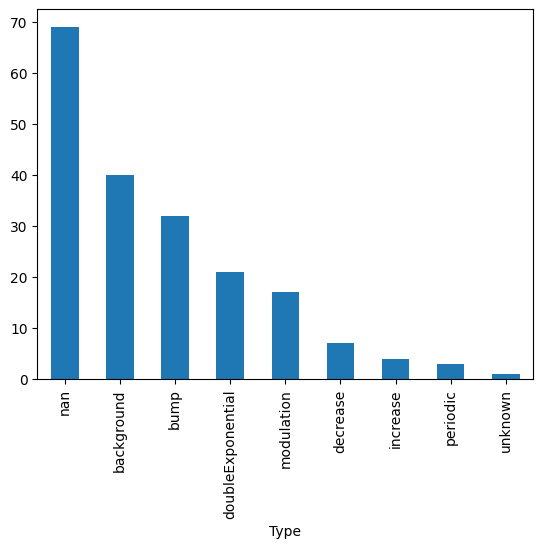

In [19]:
res_df['Type'].value_counts(dropna=False).plot(kind='bar')

The *sub*`DataFrame`s for VAE...

In [20]:
vae_selected_df = res_df[res_df['Selected by'] == 'VAE'].drop(columns=['Selected by'])

, AR, ...

In [21]:
ar_selected_df = res_df[res_df['Selected by'] == 'AR'].drop(columns=['Selected by'])

...and *random*

In [22]:
random_selected_df = res_df[pd.isna(res_df['Selected by'])].drop(columns=['Selected by'])
random_selected_df.shape

(80, 9)

Another *sub*`DataFrame` with those that were annotated as `Interesting` (the latter encompass signals identified as *background*)

In [23]:
interesting_df = res_df[res_df['Label'] == 'Interesting']
interesting_df.shape

(125, 10)

# Precision

*Precision* is computed dismissing "interesting" events that are *background*. Overall precision *in the selection*: out of the total number of selected windows (by any of the algorithms or randomly), how many are interesting (not background).

In [24]:
# overall_precision = ((res_df['Label'] == 'Interesting') & (res_df['Type'] != 'background')).sum().item() / len(res_df)
# overall_precision = res_df['Event'].sum().item() / len(res_df)
overall_precision = res_df['Event'].mean().item()
overall_precision

0.4381443298969072

## VAE

In [25]:
# vae_precision = ((vae_selected_df['Label'] == 'Interesting') & (vae_selected_df['Type'] != 'background')).sum().item() / len(vae_selected_df)
vae_precision = vae_selected_df['Event'].mean().item()
vae_precision

0.7543859649122807

## AR

In [26]:
# ar_precision = ((ar_selected_df['Label'] == 'Interesting') & (ar_selected_df['Type'] != 'background')).sum().item() / len(ar_selected_df)
ar_precision = ar_selected_df['Event'].mean().item()
ar_precision

0.40350877192982454

## Random

In [27]:
# random_precision = ((random_selected_df['Label'] == 'Interesting') & (random_selected_df['Type'] != 'background')).sum().item() / len(random_selected_df)
random_precision = random_selected_df['Event'].mean().item()
random_precision

0.2375

# Recall

It requires a probability/score for every point...

In [28]:
# vae_recall = interesting_df.index.isin(vae_selected_df.index).sum().item()
# vae_recall

# Distances

A `DataFrame` with the *reference* windows...

In [29]:
selected_df = pd.read_excel(reference_windows_file)
selected_df

,# window,start,end,tar file,source,signal
0,8248,2014-06-03 10:18:04.165,2014-06-03 16:01:27.685,0740290301.tar,P0740290301PNX000SRCTSR8002.FTZ,0740290301/P0740290301PNX000SRCTSR8002
1,12392,2009-06-03 15:06:00.097,2009-06-03 20:49:23.617,0605950101.tar,P0605950101PNX000SRCTSR8001.FTZ,0605950101/P0605950101PNX000SRCTSR8001
2,16827,2014-04-13 18:02:03.317,2014-04-13 23:45:26.837,0720173901.tar,P0720173901PNX000SRCTSR8001.FTZ,0720173901/P0720173901PNX000SRCTSR8001
3,26795,2012-10-23 22:03:27.911,2012-10-24 03:46:51.431,0690744401.tar,P0690744401PNX000SRCTSR8002.FTZ,0690744401/P0690744401PNX000SRCTSR8002


...and their indexes

In [30]:
i_reference_windows = selected_df['# window'].values
i_reference_windows

array([ 8248, 12392, 16827, 26795])

## VAE

The `DataFrame` with the latent space (embeddings) obtained from the VAE

In [31]:
vae_df = pd.read_parquet(res_dir / 'vae.parquet')
vae_df.head()

,start,end,tar file,source,z_sd_1,z_sd_2,z_sd_3,z_sd_4,z_sd_5,z_sd_6,...,cluster in projected space,RA,DEC,CRA,CDEC,main_type,other_types,main_id,# window,signal
0,2018-06-08 20:14:41.569583,2018-06-09 01:58:05.089583,0821871301.tar,P0821871301PNX000SRCTSR8001.FTZ,0.999998,0.999772,1.000190,0.998747,0.780159,1.000607,...,1,201.089746,31.447543,201.090309,31.447292,QSO,*|Opt|QSO|Rad,SDSS J132421.64+312650.8,0,0821871301/P0821871301PNX000SRCTSR8001
1,2018-06-08 20:14:41.569583,2018-06-09 01:58:05.089583,0821871301.tar,P0821871301PNX000SRCTSR8002.FTZ,0.999374,1.002197,1.001261,1.002477,0.623145,1.000467,...,1,200.941274,31.658391,200.941912,31.658179,QSO,Opt|QSO,SDSS J132346.07+313929.7,0,0821871301/P0821871301PNX000SRCTSR8002
2,2018-06-08 20:30:01.369583,2018-06-09 02:13:24.889583,0821871301.tar,P0821871301PNX000SRCTSR8001.FTZ,1.000619,0.999929,1.000328,0.998699,0.774997,1.001200,...,1,201.089746,31.447543,201.090309,31.447292,QSO,*|Opt|QSO|Rad,SDSS J132421.64+312650.8,1,0821871301/P0821871301PNX000SRCTSR8001
3,2018-06-08 20:30:01.369583,2018-06-09 02:13:24.889583,0821871301.tar,P0821871301PNX000SRCTSR8002.FTZ,0.998386,1.002677,0.999767,1.002210,0.612224,0.999059,...,1,200.941274,31.658391,200.941912,31.658179,QSO,Opt|QSO,SDSS J132346.07+313929.7,1,0821871301/P0821871301PNX000SRCTSR8002
4,2018-06-08 20:45:21.169583,2018-06-09 02:28:44.689583,0821871301.tar,P0821871301PNX000SRCTSR8001.FTZ,0.999591,0.999398,0.999994,0.999093,0.803387,1.000595,...,1,201.089746,31.447543,201.090309,31.447292,QSO,*|Opt|QSO|Rad,SDSS J132421.64+312650.8,2,0821871301/P0821871301PNX000SRCTSR8001


It includes mean and standard deviation

In [32]:
z_mean = vae_df.filter(regex=r'z_\d+').values
z_sd = vae_df.filter(regex=r'z_sd_\d+').values
z_mean.shape, z_sd.shape

((30856, 10), (30856, 10))

The Wasserstein distance between *every one* of the (mean and standard deviation for the) reference windows and the rest.

In [33]:
vae_distances = jax.vmap(
    trapallada.results.analysis.wasserstein_between_one_and_many_gaussians, in_axes=(0, 0, None, None)
    )(
        z_mean[i_reference_windows],
        z_sd[i_reference_windows],
        z_mean, z_sd
)
# assert (vae_distances[jnp.arange(len(i_reference_windows)), i_reference_windows] == 0.0).all().item()
vae_distances.shape

(4, 30856)

The minimum is taken

In [34]:
vae_rank = vae_distances.min(axis=0)
assert (vae_rank[i_reference_windows] == 0.0).all().item()

## AR

In [35]:
# with (res_dir / 'ar_model.txt').open('r') as f:
#     ar_file = f.readline()

In [36]:
# with (res_dir / 'ar_model.txt').open('r') as f:
#     ar_file = f.readline()
# ar_df = pd.read_parquet(ar_file)
# ar_df.head()

In [37]:
# z_mean = ar_df.filter(regex=r'z_\d+').values
# z_mean.shape

In [38]:
# def euclidean_distance_between_one_and_many(x, Y):
#     return jnp.sqrt(jnp.sum((x[None, :] - Y) ** 2, axis=-1))
# euclidean_distance_between_one_and_many(z_mean[0], z_mean)

In [39]:
# ar_distances = jax.vmap(
#     euclidean_distance_between_one_and_many, in_axes=(0, None)
#     )(
#         z_mean[i_reference_windows],
#         z_mean
# )
# # assert (ar_distances[jnp.arange(len(i_reference_windows)), i_reference_windows] == 0.0).all().item()

In [40]:
# ar_rank = ar_distances.min(axis=0)
# assert (ar_rank[i_reference_windows] == 0.0).all().item()

In [41]:
# ar_rank

# Latent space

Results from the simulation are loaded

In [42]:
# ds, positions_df, model, training_df, parameters = trapallada.results.analysis.load_dir(res_dir)
ds, _, model, _, parameters = trapallada.results.analysis.load_dir(res_dir) # type: ignore

In [43]:
batch_size = 128
dl = DataLoader(ds, batch_size=batch_size, shuffle=False)

The log-likelihood and the KL divergence *for every window* in the dataset...

In [44]:
log_likelihood, kl_divergence = trapallada.results.analysis.data_losses(
    model,
    dl,
    parameters['loss']['x_sd'],
    parameters['training']['mask_non_gti_intervals'],
    jr.PRNGKey(parameters['PRNG seeds']['sampling']['validation set']),
)

...are used to compute the lossess, i.e., `-ELBO`

In [45]:
losses_df = pd.DataFrame({
    "log_likelihood": jnp.concat(log_likelihood),
    "kl_divergence": jnp.concat(kl_divergence)
})
losses_df['loss'] = -losses_df['log_likelihood'] + parameters['loss']['beta'] * losses_df['kl_divergence']
assert len(ds) == len(losses_df)
losses_df

,log_likelihood,kl_divergence,loss
0,-0.164997,0.367612,0.168673
1,-0.186621,0.736171,0.193982
2,-0.164778,0.361596,0.168394
3,-0.182938,0.791616,0.190855
4,-0.164379,0.375708,0.168136
...,...,...,...
30851,-2.788693,0.508062,2.793773
30852,-2.824765,0.586417,2.830630
30853,-2.738962,0.397086,2.742933
30854,-2.816959,1.138973,2.828349


In [46]:
# score = losses_df.loc[res_df.index]['loss'].values
score = losses_df.loc[res_df.index]['log_likelihood'].values
score.shape

(194,)

The results for the AR model

In [47]:
ar_df = pd.read_parquet(res_dir.parent / 'AR' / 'ar_5_fft_False.parquet')
ar_df.head()

,start,end,tar file,source,z_1,z_2,z_3,z_4,z_5,z_6,...,cluster in projected space,RA,DEC,CRA,CDEC,main_type,other_types,main_id,# window,signal
0,2018-06-08 20:14:41.569583,2018-06-09 01:58:05.089583,0821871301.tar,P0821871301PNX000SRCTSR8001.FTZ,-0.069514,0.069419,0.066852,-0.031498,0.041259,0.029128,...,1,201.089746,31.447543,201.090309,31.447292,QSO,*|Opt|QSO|Rad,SDSS J132421.64+312650.8,0,0821871301/P0821871301PNX000SRCTSR8001
1,2018-06-08 20:14:41.569583,2018-06-09 01:58:05.089583,0821871301.tar,P0821871301PNX000SRCTSR8002.FTZ,0.048524,0.060231,0.120665,0.151738,-0.024934,0.019107,...,1,200.941274,31.658391,200.941912,31.658179,QSO,Opt|QSO,SDSS J132346.07+313929.7,0,0821871301/P0821871301PNX000SRCTSR8002
2,2018-06-08 20:30:01.369583,2018-06-09 02:13:24.889583,0821871301.tar,P0821871301PNX000SRCTSR8001.FTZ,-0.040494,0.042494,0.067655,-0.041173,-0.012557,0.031347,...,1,201.089746,31.447543,201.090309,31.447292,QSO,*|Opt|QSO|Rad,SDSS J132421.64+312650.8,1,0821871301/P0821871301PNX000SRCTSR8001
3,2018-06-08 20:30:01.369583,2018-06-09 02:13:24.889583,0821871301.tar,P0821871301PNX000SRCTSR8002.FTZ,0.042855,0.034260,0.112990,0.159840,-0.036125,0.001929,...,1,200.941274,31.658391,200.941912,31.658179,QSO,Opt|QSO,SDSS J132346.07+313929.7,1,0821871301/P0821871301PNX000SRCTSR8002
4,2018-06-08 20:45:21.169583,2018-06-09 02:28:44.689583,0821871301.tar,P0821871301PNX000SRCTSR8001.FTZ,-0.042048,0.052945,0.052545,-0.030169,-0.020930,-0.002064,...,1,201.089746,31.447543,201.090309,31.447292,QSO,*|Opt|QSO|Rad,SDSS J132421.64+312650.8,2,0821871301/P0821871301PNX000SRCTSR8001


Mean and standard deviation are stacked together

In [48]:
z_mean_sd = jnp.hstack([z_mean, z_sd])
z_mean_sd.shape

(30856, 20)

In [49]:
# y = res_df['Label'].map({'Interesting': 1, 'NOT interesting': 0}).values
y = res_df['Event'].astype(int)

A function to compare the methods based on Mahalanobis distance (through an [estimated covariance](https://scikit-learn.org/stable/modules/generated/sklearn.covariance.EmpiricalCovariance.html#sklearn.covariance.EmpiricalCovariance.mahalanobis)) and different binary classification metrics.

In [ ]:
def mahalanobis_based_metrics(
        x: Float[Array, 'window feature'],
        labels: Int[Array, 'window'],
        i_windows_of_interest: Int[Array, 'window'],
        min_precision: float = 0.7
    ) -> tuple[float, float, float]:

    # covariance matrix (and mean) is estimated...
    cov = EmpiricalCovariance().fit(x)

    # Mahalanobis distance (given the above covariance) from every sample to the mean (a measure of *outlierness*)
    distances = cov.mahalanobis(x)

    # the distances for the windows of interest are kept as scores
    scores = distances[i_windows_of_interest]

    roc_auc = roc_auc_score(labels, scores)

    average_precision = average_precision_score(labels, scores)

    precision, recall, thr = precision_recall_curve(labels, scores)
    mask = (precision >= min_precision)
    best_recall_at_min_precision = recall[mask].max().item()

    return roc_auc, average_precision, best_recall_at_min_precision

For VAE

In [70]:
# mahalanobis_based_metrics(z_mean_sd, y, res_df.index.values)
mahalanobis_based_metrics(z_mean, y, res_df.index.values)

(0.8349703184025904, 0.7612852782365933, 0.7764705882352941)

For AR

In [66]:
mahalanobis_based_metrics(ar_df.filter(regex=r'z_\d+').values, y, res_df.index.values)

(0.5211009174311927, 0.43013079664747816, 0.0)

*Bootstrap*ped metrics

In [ ]:
# rng = np.random.default_rng(42)
# inds_pos = np.where(y==1)[0]
# inds_neg = np.where(y==0)[0]

# B = 10_000          # ≤ 2 s on a laptop
# stats = np.empty((B, 3))   # AUROC, AUPRC, R@90P
# for b in range(B):
#     boot_pos = rng.choice(inds_pos, size=len(inds_pos), replace=True)
#     boot_neg = rng.choice(inds_neg, size=len(inds_neg), replace=True)
#     boot = np.concatenate([boot_pos, boot_neg])
#     y_b, s_b = y[boot], score[boot]
#     stats[b,0] = roc_auc_score(y_b, s_b)
#     stats[b,1] = average_precision_score(y_b, s_b)
#     p,r,_ = precision_recall_curve(y_b, s_b)
#     stats[b,2] = r[p>=0.90].max(initial=0)


In [ ]:
# ci_lower  = np.percentile(stats,  2.5, axis=0)
# ci_upper  = np.percentile(stats, 97.5, axis=0)
# ci_lower, ci_upper

(array([0.83014493, 0.90444551, 0.592     ]),
 array([0.92672464, 0.96285953, 0.904     ]))

In [ ]:
# perm = np.empty(B)
# for b in range(B):
#     perm[b] = average_precision_score(y, rng.permutation(score))
# p_val = (perm >= obs_average_precision_score).mean()
# p_val

np.float64(0.0)

In [67]:
# # losses_df.sort_values(by='log_likelihood', ascending=False)
# losses_df.sort_values(by='loss', ascending=False)